<a href="https://colab.research.google.com/github/mhsahel/mental-health-score-prediction/blob/main/Mental_Health_Score.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [133]:
import numpy as np
import matplotlib.pyplot as plt
import   seaborn as sns
import pandas as pd

In [134]:
df = pd.read_csv("/content/mental_health_score.csv")

In [135]:
print(f"Rows :{df.shape[0]}\nColumns: {df.shape[1]}")

Rows :5000
Columns: 13


In [136]:
# First 5 datas
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [137]:
# check the duplicated
dupli = df.duplicated().sum()
print(f"Duplicates : {dupli}")

Duplicates : 2


In [138]:
# check those duplicat rows
df[df.duplicated()]

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
2405,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
2463,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5


In [139]:
# check nulls values
df.isna().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


In [140]:
# check descrivtive
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [141]:
# check all data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


# perform the EDA(exploratiry data analysis)

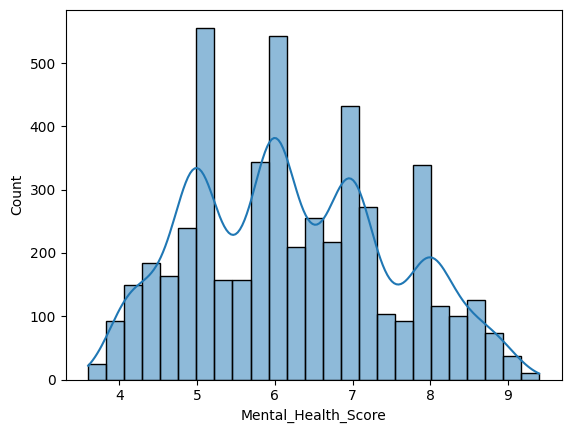

In [142]:
# check the target column first by using hist plot
sns.histplot(df['Mental_Health_Score'], kde = True)
plt.show()

# Check the correlations of all numerical columns

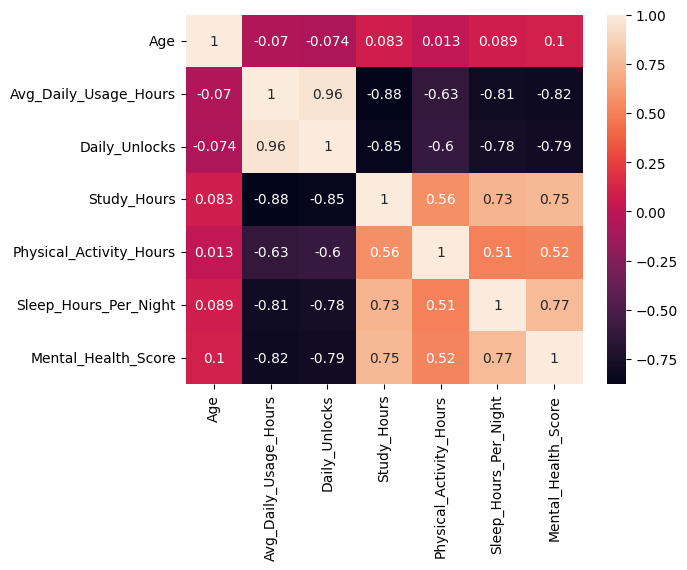

In [143]:
# using heatmap with over all the numerical columns
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [144]:
# select all categorical column
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
cat_cols

['Gender',
 'Country',
 'Academic_Level',
 'Most_Used_Platform',
 'Purpose_Of_Use',
 'Stress_Level']

In [145]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [146]:
# relationship between stress_level vs mental_health_score
stress_lvl = df['Stress_Level'].unique().tolist()

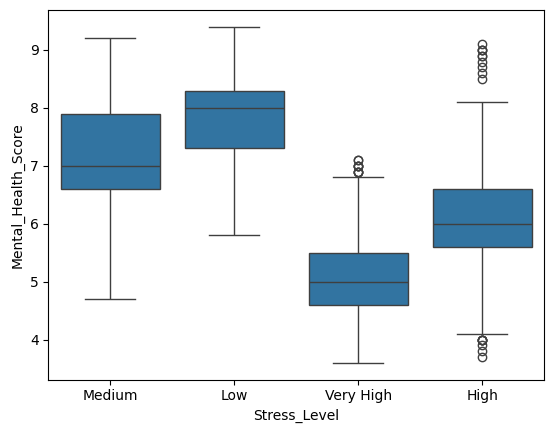

In [147]:
#check the outliers with bloxplot
sns.boxplot(data = df, x = 'Stress_Level', y = 'Mental_Health_Score')
plt.show()

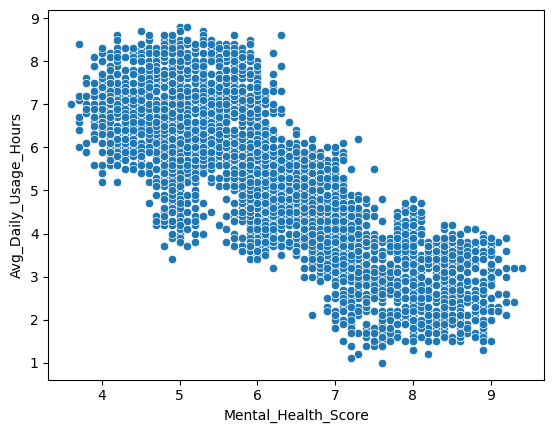

In [148]:
# check daily usage with the mental score
sns.scatterplot(data = df , x ='Mental_Health_Score', y = 'Avg_Daily_Usage_Hours')
plt.show()

<Axes: xlabel='Mental_Health_Score', ylabel='Sleep_Hours_Per_Night'>

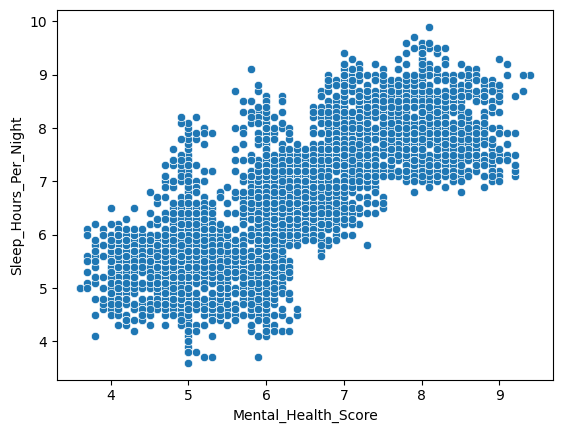

In [149]:
# check sleep hours  with the mental score
sns.scatterplot(data = df , x ='Mental_Health_Score', y = 'Sleep_Hours_Per_Night')

In [150]:
df['Most_Used_Platform'].value_counts()

,count
Most_Used_Platform,
Instagram,1130
TikTok,918
Facebook,719
LinkedIn,523
YouTube,491
Twitter,462
Snapchat,420
WhatsApp,175
LINE,50


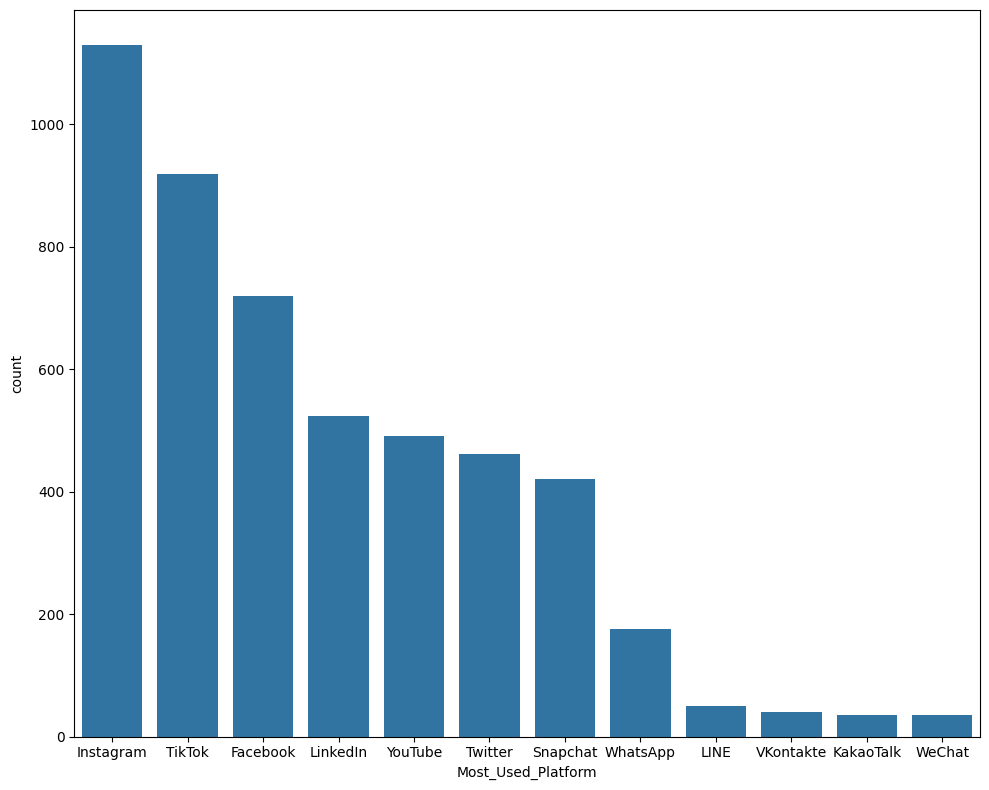

In [151]:
# check which platform are mostly used
plt.figure(figsize=(10,8))
sns.countplot(order =  df['Most_Used_Platform'].value_counts().index , x = df['Most_Used_Platform'])
plt.tight_layout()

<Axes: xlabel='Mental_Health_Score', ylabel='Study_Hours'>

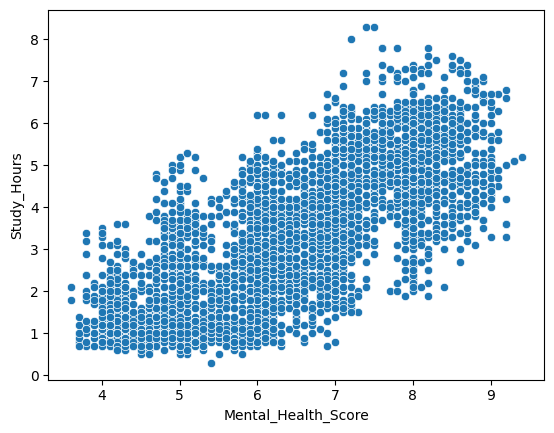

In [152]:
# checking study hours vs mental_health_score
sns.scatterplot(data = df , x='Mental_Health_Score', y = 'Study_Hours')

# check the outliers  using IQR methods

In [153]:
numeric_features = df.select_dtypes(include = 'number')
q1= numeric_features.quantile(0.25)
q3 = numeric_features.quantile(0.75)
IQR =q3 - q1

In [154]:
lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

In [155]:
outliers = (numeric_features > upper_bound) | (numeric_features<lower_bound)

# Data Cleaning Process

In [156]:
# finding the duplicates from the my dataset

print(f"The number of duplicates = {df.duplicated().sum()}")

The number of duplicates = 2


In [157]:
# checking which two are duplicates for further droping if needed
df[df.duplicated(keep = False)]

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
886,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
1870,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5
2405,19,Female,Other,Undergraduate,LinkedIn,Education,6.1,202,1.0,2.1,5.8,High,4.1
2463,21,Male,USA,Undergraduate,Snapchat,Entertainment,3.9,126,5.1,2.6,7.1,Low,7.5


In [158]:
#drop the duplicates
df.drop_duplicates(inplace = True)


In [159]:
df.shape

(4998, 13)

In [160]:
df.duplicated().sum()

np.int64(0)

In [161]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

In [162]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.751160,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.667282,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [163]:

num_cols = df.select_dtypes(include='number')
num_cols.skew()

,0
Age,0.155008
Avg_Daily_Usage_Hours,0.005575
Daily_Unlocks,0.002309
Study_Hours,0.436125
Physical_Activity_Hours,0.053288
Sleep_Hours_Per_Night,0.123919
Mental_Health_Score,0.207086


In [164]:
numeric_col = df.select_dtypes(include = 'number').columns.tolist()
numeric_col

['Age',
 'Avg_Daily_Usage_Hours',
 'Daily_Unlocks',
 'Study_Hours',
 'Physical_Activity_Hours',
 'Sleep_Hours_Per_Night',
 'Mental_Health_Score']

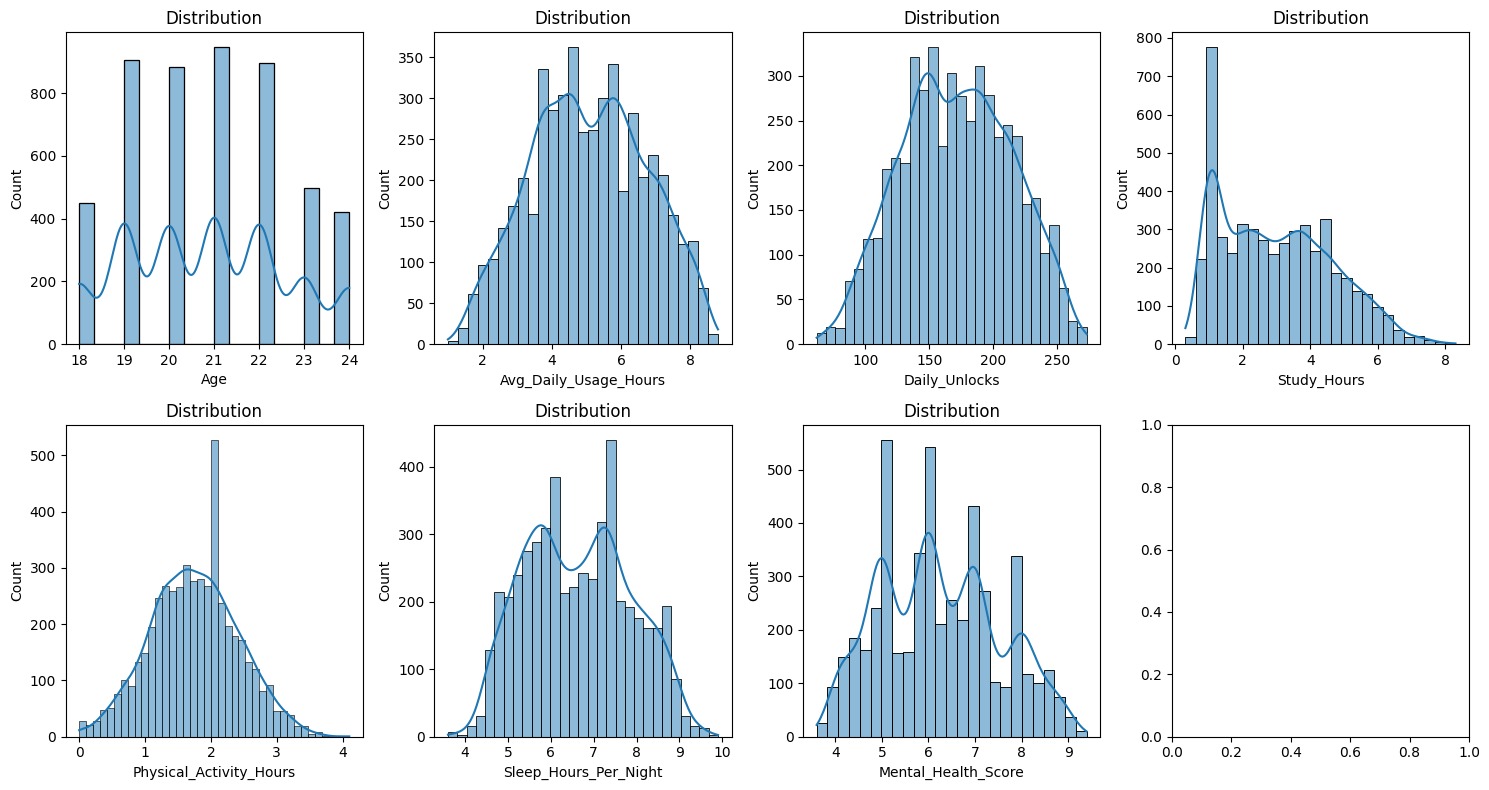

In [165]:
fig , axes = plt.subplots(ncols = 4, nrows = 2 , figsize =(15,8))
axes = axes.flatten()
for i , col in enumerate(numeric_col):
  sns.histplot(data = df , ax=axes[i], x = col, kde = True)
  axes[i].set_title("Distribution")
plt.tight_layout()
plt.show()

#Feature Engineering


In [166]:
top_countries = df['Country'].value_counts().index[1:11].tolist()
def select_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [167]:
top_countries

['India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France',
 'Spain']

In [168]:
df['Country'].value_counts()

,count
Country,
Other,1879
India,389
USA,354
Canada,230
Australia,198
...,...
Armenia,1
Bosnia,1
Kuwait,1


In [169]:

df['Country'] = df['Country'].apply(select_countries)

In [170]:

df['Country'].value_counts()

,count
Country,
Other,3148
India,389
USA,354
Canada,230
Australia,198
UK,185
Germany,136
Turkey,94
Mexico,94


# Train Test split

In [171]:

from sklearn.model_selection import train_test_split

skwed_col         = ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Country"]


feature_col = skwed_col + other_numeric_cols + ordinal_col + normal_col
X = df[feature_col]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)


In [172]:
df['Stress_Level'].value_counts()

,count
Stress_Level,
Very High,1621
High,1439
Medium,1295
Low,643


# prepocessing the columns with creating Pipelins

In [173]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder,OneHotEncoder
skew_pipeline = make_pipeline(FunctionTransformer(np.log1p),StandardScaler())

other_num_pipeline = make_pipeline(StandardScaler())

ordinal_pipeline = make_pipeline(
OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))

one_hot_pipeline = make_pipeline(OneHotEncoder(handle_unknown='ignore'))

In [174]:
from sklearn.compose import ColumnTransformer
preprocess= ColumnTransformer(transformers=[

                                     ('skewed_pipelin', skew_pipeline,skwed_col),
                                     ('other_col_pipeline',other_num_pipeline,other_numeric_cols),
                                     ('ordinal_pipeline',ordinal_pipeline,ordinal_col),
                                     ('one_hot_pipeline',one_hot_pipeline,normal_col)
])
preprocess

ColumnTransformer(transformers=[('skewed_pipelin',
                                 Pipeline(steps=[('functiontransformer',
                                                  FunctionTransformer(func=<ufunc 'log1p'>)),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['Study_Hours']),
                                ('other_col_pipeline',
                                 Pipeline(steps=[('standardscaler',
                                                  StandardScaler())]),
                                 ['Age', 'Avg_Daily_Usage_Hours',
                                  'Daily_Unlocks', 'Physical_Activity_Hours',
                                  'Sleep_Hours_Per_Night']),
                                ('ordinal_pipeline',
                                 Pipeline(steps=[('ordinalencoder',
                                                  OrdinalEncoder(categories=[['Low',
                                                                              'Medium',
                                                                              'High',
                                                                              'Very '
                                                                              'High']]))]),
                                 ['Stress_Level']),
                                ('one_hot_pipeline',
                                 Pipeline(steps=[('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender', 'Academic_Level',
                                  'Most_Used_Platform', 'Purpose_Of_Use',
                                  'Country'])])

# Base -: Model Linear Regression

In [175]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
lr_pipeline = make_pipeline(preprocess, LinearRegression())
lr_pipeline

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('skewed_pipelin',
                                                  Pipeline(steps=[('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('other_col_pipeline',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Phy...
                                                 ('ordinal_pipeline',
                                                  Pipeline(steps=[('ordinalencoder',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('one_hot_pipeline',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use',
                                                   'Country'])])),
                ('linearregression', LinearRegression())])

In [176]:
lr_pipeline.fit(X_train , y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('skewed_pipelin',
                                                  Pipeline(steps=[('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('other_col_pipeline',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Phy...
                                                 ('ordinal_pipeline',
                                                  Pipeline(steps=[('ordinalencoder',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('one_hot_pipeline',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use',
                                                   'Country'])])),
                ('linearregression', LinearRegression())])

In [177]:
lr_pred_test = lr_pipeline.predict(X_test)
lr_pred_train = lr_pipeline.predict(X_train)


# Checking Accuracy Of The Model

In [178]:
lr_r2_testing=r2_score(y_test , lr_pred_test)
lr_r2_training=r2_score(y_train , lr_pred_train)

print(f"Training R2_Accuracy: {lr_r2_training}")
print(f"Testing R2_Accuracy: {lr_r2_testing}")

Training R2_Accuracy: 0.7284451141767213
Testing R2_Accuracy: 0.7431949512902988


In [179]:
rf_mse_train = mean_squared_error(y_train , lr_pred_train)
rf_mse_test = mean_squared_error(y_test , lr_pred_test)
print(f"Training Mean Squared Error: {rf_mse_train }")
print(f"Testing Mean Squared Error: {rf_mse_test}")

Training Mean Squared Error: 0.4292480436706398
Testing Mean Squared Error: 0.451046510712849


In [180]:
rf_mae_train = mean_absolute_error(y_train , lr_pred_train)
rf_mae_test = mean_absolute_error(y_test , lr_pred_test)
print(f"Training Mean Absolute Error: {rf_mae_train }")
print(f"Testing Mean Absolute Error: {rf_mae_test}")

Training Mean Absolute Error: 0.5124270241003328
Testing Mean Absolute Error: 0.5302565031464506


# Random_Forest Model


In [181]:
from sklearn.ensemble import RandomForestRegressor
rf_pipe= make_pipeline(preprocess , RandomForestRegressor(random_state=42))


In [182]:
rf_pipe.fit(X_train,y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('skewed_pipelin',
                                                  Pipeline(steps=[('functiontransformer',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Study_Hours']),
                                                 ('other_col_pipeline',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_Daily_Usage_Hours',
                                                   'Daily_Unlocks',
                                                   'Phy...
                                                  Pipeline(steps=[('ordinalencoder',
                                                                   OrdinalEncoder(categories=[['Low',
                                                                                               'Medium',
                                                                                               'High',
                                                                                               'Very '
                                                                                               'High']]))]),
                                                  ['Stress_Level']),
                                                 ('one_hot_pipeline',
                                                  Pipeline(steps=[('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Academic_Level',
                                                   'Most_Used_Platform',
                                                   'Purpose_Of_Use',
                                                   'Country'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=42))])

In [183]:
rf_pred_train = rf_pipe.predict(X_train)
rf_pred_test = rf_pipe.predict(X_test)

In [184]:
rf_r2_score_train = r2_score(y_train , rf_pred_train)
rf_r2_score_test = r2_score(y_test , rf_pred_test)

print(f"Training R2_Accuracy for random forest: {rf_r2_score_train}\n")

print(f"Testing R2_Accuracy for random forest: {rf_r2_score_test}\n")
rf_mse_train = mean_squared_error(y_train , rf_pred_train)
rf_mse_test = mean_squared_error(y_test , rf_pred_test)

print(f"Training Mean Squared Error for random forest: {rf_mse_train}\n")

print(f"Testing Mean Squared Error for random forest: {rf_mse_test}\n")
rf_mae_train = mean_absolute_error(y_train , rf_pred_train)
rf_mae_test = mean_absolute_error(y_test , rf_pred_test)

print(f"Training Mean Absolute Error for random forest: {rf_mae_train}\n")

print(f"Testing Mean Absolute Error for random forest: {rf_mae_test}")

Training R2_Accuracy for random forest: 0.9811530095291167

Testing R2_Accuracy for random forest: 0.8803226732431098

Training Mean Squared Error for random forest: 0.02979152359634082

Testing Mean Squared Error for random forest: 0.21019851796666672

Training Mean Absolute Error for random forest: 0.12488862206975422

Testing Mean Absolute Error for random forest: 0.3423140666666668


In [185]:
params = {'randomforestregressor__n_estimators':[100,300,500],'randomforestregressor__max_depth':[10,6,9],'randomforestregressor__max_leaf_nodes':[2,4,6],'randomforestregressor__min_samples_leaf':[2,3,4],'randomforestregressor__min_samples_split':[2,5,10]}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
rs = RandomizedSearchCV(estimator=rf_pipe, param_distributions=params,n_jobs=-1,n_iter=10,cv=5,scoring='r2')
rs.fit(X_train , y_train)

In [ ]:
rf_rand_pred_train = rs.predict(X_train)
rf_rand__pred_test = rs.predict(X_test)

In [ ]:

print(f"Training R2_Accuracy for random forest after tuning: {r2_score(y_train ,rf_rand_pred_train)}\n")

print(f"Testing R2_Accuracy for random forest after tuning: {r2_score(y_test , rf_rand__pred_test )}\n")


print(f"Training Mean Squared Error for random forest after tuning: {mean_squared_error(y_train , rf_rand_pred_train)}\n")

print(f"Testing Mean Squared Error for random forest after tuning: {mean_squared_error(y_test ,rf_rand__pred_test )}\n")



print(f"Training Mean Absolute Error for random forest after tuning: {mean_absolute_error(y_train , rf_rand_pred_train)}\n")

print(f"Testing Mean Absolute Error for random forest after tuning: {mean_absolute_error(y_test , rf_rand__pred_test )}")

In [ ]:
rf_tuned_mae= mean_absolute_error(y_test , rf_rand__pred_test )

In [ ]:
print(f"Best all parameters{rs.best_params_}")

Choosing Best Model

In [ ]:
from sklearn.metrics import mean_squared_error

# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred_test))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred_test))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = rs.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = rs.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)

# Create a DataFrame to consolidate results

# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_score_test, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_score_train , r2_tuned_training],
    'MAE': [rf_mae_test, rf_mae_test, rf_tuned_mae],  # rf_mae_test is used for both based on your previously executed cells
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)
